In [2]:
import numpy as np
import matplotlib.pyplot as plt
from spectral import envi
# import tools
from matplotlib.patches import Rectangle
from stitching_functions import convert_to_reflectance

## IQ

In [ ]:
folder = '../data/IQ/raw/pigments'  # folder of given acquisition
num = 954  # number corresponding to the acquisition

path_raw = f"{folder}/capture/{num}.hdr"
path_dark = f"{folder}/capture/DARKREF_{num}.hdr"

# Opening hsi cube and dark reference.
cube_og = envi.open(path_raw).asarray()
dark = envi.open(path_dark).asarray()
# cube_og.shape, dark.shape

y, pxls = 300, 5  # y of white reference + how many rows for taking the average white
band = 100 

cube = cube_og.transpose(1,0,2) # Transposing to be "right side up"

fig, ax = plt.subplots(ncols=2, nrows=1, figsize=(10, 5))
ax[0].imshow(cube[:, :, band])  # Plotting to check
ax[0].add_patch(Rectangle(xy=(0,y), width=512, height=pxls, ec='red', fc='none', ls='-', lw=1))  # Rectangle to white ref area
ax[0].set_title('RAW')

# Snip the white reference
white = cube[y:y+pxls]
print(white.shape)
white = np.average(white, axis = 0, keepdims=True)  # avg white

refl = convert_to_reflectance(raw=cube, white=white, dark=dark)
ax[1].imshow(refl[:, :, band])
ax[1].set_title('REFLECTANCE')

plt.show()

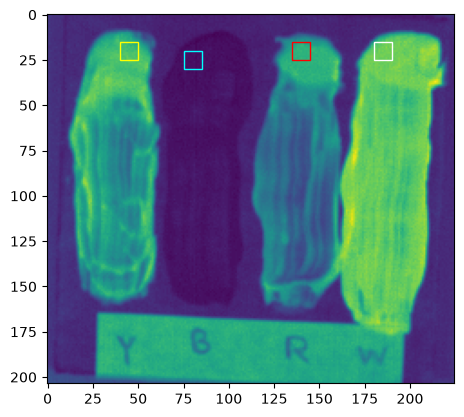

In [66]:

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

# refl = np.load('../data/FX17/reflectance/pigments.npy')
refl = np.load('../data/IQ/reflectance/pigments.npy')


# x, y, width, height
w, h = 10, 10

yellow = (40,  15, w, h)
blue   = (75, 20, w, h)
red    = (135, 15, w, h)
white  = (180, 15, w, h)

fig, ax = plt.subplots()

ax.imshow(refl[:, :, -20])
ax.add_patch(Rectangle((yellow[0], yellow[1]), yellow[2], yellow[3],
                       edgecolor='yellow', facecolor='none'))

ax.add_patch(Rectangle((blue[0], blue[1]), blue[2], blue[3],
                       edgecolor='cyan', facecolor='none'))

ax.add_patch(Rectangle((red[0], red[1]), red[2], red[3],
                       edgecolor='red', facecolor='none'))

ax.add_patch(Rectangle((white[0], white[1]), white[2], white[3],
                       edgecolor='white', facecolor='none'))

plt.show()

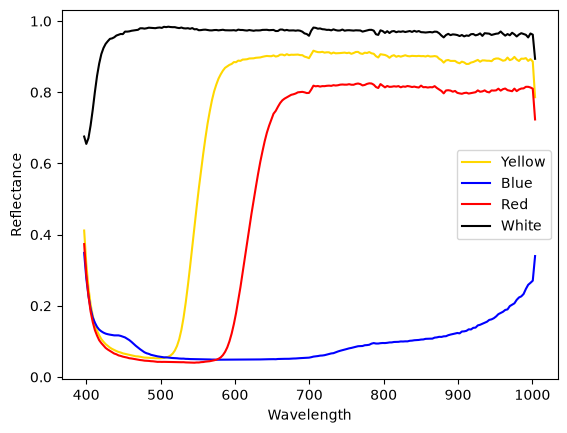

In [67]:
# computing mean spectra

yellow_spec = refl[
    yellow[1]:yellow[1]+yellow[3],  # crop y
    yellow[0]:yellow[0]+yellow[2],  # crop x
    :                               # keep all wls
].mean(axis=(0, 1))

blue_spec = refl[
    blue[1]:blue[1]+blue[3],
    blue[0]:blue[0]+blue[2],
    :
].mean(axis=(0, 1))

red_spec = refl[
    red[1]:red[1]+red[3],
    red[0]:red[0]+red[2],
    :
].mean(axis=(0, 1))

white_spec = refl[
    white[1]:white[1]+white[3],
    white[0]:white[0]+white[2],
    :
].mean(axis=(0, 1))



# ----------------- plotting -----------------------
plt.figure()

wls = np.load('../data/IQ/wls.npy')

plt.plot(wls, yellow_spec, color='gold', label='Yellow')
plt.plot(wls, blue_spec, color='blue', label='Blue')
plt.plot(wls, red_spec, color='red', label='Red')
plt.plot(wls, white_spec, color='black', label='White')

plt.xlabel("Wavelength")
plt.ylabel("Reflectance")
plt.legend()

plt.show()

In [ ]:
# # Saving them all
# savepath='../data/IQ/gt'
# np.save(f'{savepath}/blue.npy', blue_spec)
# np.save(f'{savepath}/red.npy', red_spec)
# np.save(f'{savepath}/yellow.npy', yellow_spec)
# np.save(f'{savepath}/white.npy', white_spec)

## FX10

- pigments imaged using scanner + software --> output ENVI

In [ ]:
folder = '../data/FX10/raw'  # folder where the raw data is
name = 'pigments_pure_2026-10-21_14-15-52'  # name associated with capture  

path_raw = f"{folder}/{name}/capture/{name}.hdr"

# Getting wavelengths
wls = envi.open(path_raw).metadata['wavelength']
wls = np.asarray(wls, dtype=float)
np.save('../data/FX10/wls.npy', wls)

In [ ]:
# folder = '../data/FX10/raw'  # folder where the raw data is
# name = 'pigments_pure_2026-10-21_14-15-52'  # name associated with capture  

# path_raw = f"{folder}/{name}/capture/{name}.hdr"
# path_dark = f"{folder}/{name}/capture/DARKREF_{name}.hdr"
# path_white = f"{folder}/{name}/capture/WHITEREF_{name}.hdr"

# # Opening hsi cube and dark reference.
# cube = envi.open(path_raw).asarray()
# dark = envi.open(path_dark).asarray()
# white = envi.open(path_white).asarray()

# print(cube.shape, dark.shape, white.shape)

# dark = np.mean(dark, axis=0, keepdims=True)
# white = np.mean(white, axis=0, keepdims=True)
# print(cube.shape, dark.shape, white.shape)

# # cube = cube_og.transpose(1,0,2) # Transposing to be "right side up"
# band  = 100
# fig, ax = plt.subplots(ncols=2, nrows=1, figsize=(10, 5))
# ax[0].imshow(cube[:, :, band])  # Plotting to check
# ax[0].set_title('RAW')

# refl = convert_to_reflectance(raw=cube, white=white, dark=dark)
# ax[1].imshow(refl[:, :, band])
# ax[1].set_title('REFKECTANCE')

# plt.show()

In [ ]:
# Cropping image and saving it
#  from cube_tools import CubeClipper

# refl_flipped = np.flip(refl, axis=1)

# %matplotlib widget
# clipper = CubeClipper(refl_flipped, band=130, out_dir="clips")

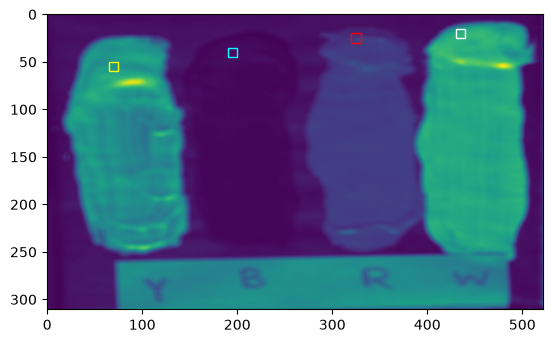

In [59]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

refl = np.load('../data/FX10/reflectance/pigments.npy')

# x, y, width, height
w, h = 10, 10

yellow = (65,  50, w, h)
blue   = (190, 35, w, h)
red    = (320, 20, w, h)
white  = (430, 15, w, h)

fig, ax = plt.subplots()

ax.imshow(refl[:, :, 80])
ax.add_patch(Rectangle((yellow[0], yellow[1]), yellow[2], yellow[3],
                       edgecolor='yellow', facecolor='none'))

ax.add_patch(Rectangle((blue[0], blue[1]), blue[2], blue[3],
                       edgecolor='cyan', facecolor='none'))

ax.add_patch(Rectangle((red[0], red[1]), red[2], red[3],
                       edgecolor='red', facecolor='none'))

ax.add_patch(Rectangle((white[0], white[1]), white[2], white[3],
                       edgecolor='white', facecolor='none'))

plt.show()

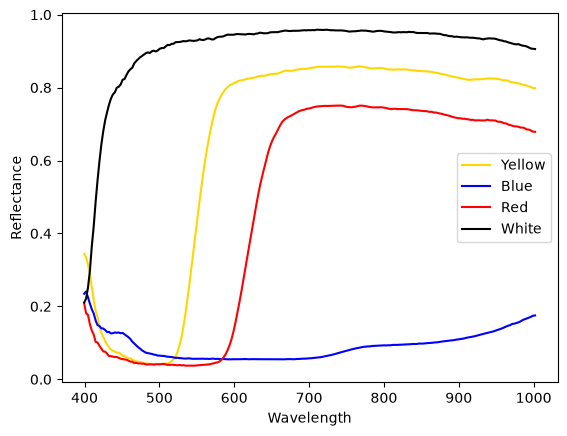

In [60]:
# computing mean spectra

yellow_spec = refl[
    yellow[1]:yellow[1]+yellow[3],  # crop y
    yellow[0]:yellow[0]+yellow[2],  # crop x
    :                               # keep all wls
].mean(axis=(0, 1))

blue_spec = refl[
    blue[1]:blue[1]+blue[3],
    blue[0]:blue[0]+blue[2],
    :
].mean(axis=(0, 1))

red_spec = refl[
    red[1]:red[1]+red[3],
    red[0]:red[0]+red[2],
    :
].mean(axis=(0, 1))

white_spec = refl[
    white[1]:white[1]+white[3],
    white[0]:white[0]+white[2],
    :
].mean(axis=(0, 1))



# ----------------- plotting -----------------------
plt.figure()
wls = np.load('../data/FX10/wls.npy')
plt.plot(wls, yellow_spec, color='gold', label='Yellow')
plt.plot(wls, blue_spec, color='blue', label='Blue')
plt.plot(wls, red_spec, color='red', label='Red')
plt.plot(wls, white_spec, color='black', label='White')

plt.xlabel("Wavelength")
plt.ylabel("Reflectance")
plt.legend()

plt.show()

In [ ]:
# # Saving them all
# savepath='../data/FX10/gt'
# np.save(f'{savepath}/blue.npy', blue_spec)
# np.save(f'{savepath}/red.npy', red_spec)
# np.save(f'{savepath}/yellow.npy', yellow_spec)
# np.save(f'{savepath}/white.npy', white_spec)

## FX17

In [ ]:
# # Getting raw data + white and dark references

# raw = '../data/FX17/raw/pigments/capture/testy_pigms_2026-06-12_06-28-34.hdr'
# white = '../data/FX17/raw/pigments/capture/WHITEREF_testy_pigms_2026-06-12_06-28-34.hdr'
# dark = '../data/FX17/raw/pigments/capture/DARKREF_testy_pigms_2026-06-12_06-28-34.hdr'

# raw = envi.open(raw).asarray()
# white = envi.open(white).asarray()
# dark = envi.open(dark).asarray()


# # Taking avg values of white and dark for reflectance calculations
# white_mean = np.mean(white, axis=0, keepdims=True)
# dark_mean = np.mean(dark, axis=0, keepdims=True)

# refl = convert_to_reflectance(raw=raw, white=white_mean, dark=dark_mean)
# refl = np.flip(refl, axis=1)  # flipping to get right orientation


# ... after this, used the clipping widget to clip correct area and saved it in FX17/reflectance/pigments.npy

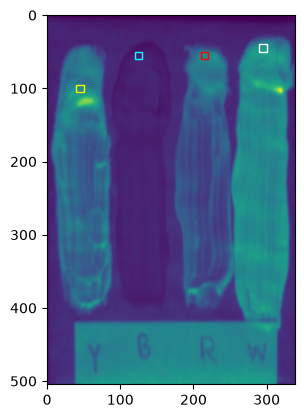

In [62]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

refl = np.load('../data/FX17/reflectance/pigments.npy')

# x, y, width, height
w, h = 10, 10

yellow = (40,  95, w, h)
blue   = (120, 50, w, h)
red    = (210, 50, w, h)
white  = (290, 40, w, h)

fig, ax = plt.subplots()

ax.imshow(refl[:, :, 20])
ax.add_patch(Rectangle((yellow[0], yellow[1]), yellow[2], yellow[3],
                       edgecolor='yellow', facecolor='none'))

ax.add_patch(Rectangle((blue[0], blue[1]), blue[2], blue[3],
                       edgecolor='cyan', facecolor='none'))

ax.add_patch(Rectangle((red[0], red[1]), red[2], red[3],
                       edgecolor='red', facecolor='none'))

ax.add_patch(Rectangle((white[0], white[1]), white[2], white[3],
                       edgecolor='white', facecolor='none'))

plt.show()

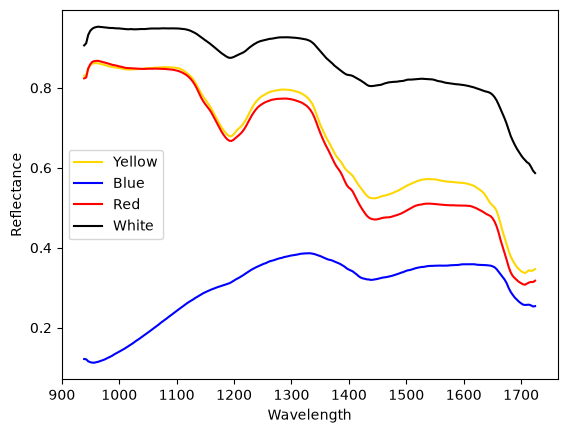

In [63]:
# computing mean spectra

yellow_spec = refl[
    yellow[1]:yellow[1]+yellow[3],  # crop y
    yellow[0]:yellow[0]+yellow[2],  # crop x
    :                               # keep all wls
].mean(axis=(0, 1))

blue_spec = refl[
    blue[1]:blue[1]+blue[3],
    blue[0]:blue[0]+blue[2],
    :
].mean(axis=(0, 1))

red_spec = refl[
    red[1]:red[1]+red[3],
    red[0]:red[0]+red[2],
    :
].mean(axis=(0, 1))

white_spec = refl[
    white[1]:white[1]+white[3],
    white[0]:white[0]+white[2],
    :
].mean(axis=(0, 1))



# ----------------- plotting -----------------------
plt.figure()

wls = np.load('../data/FX17/wls.npy')

plt.plot(wls, yellow_spec, color='gold', label='Yellow')
plt.plot(wls, blue_spec, color='blue', label='Blue')
plt.plot(wls, red_spec, color='red', label='Red')
plt.plot(wls, white_spec, color='black', label='White')

plt.xlabel("Wavelength")
plt.ylabel("Reflectance")
plt.legend()

plt.show()

In [65]:
# # Saving them all
# savepath='../data/FX17/gt'
# np.save(f'{savepath}/blue.npy', blue_spec)
# np.save(f'{savepath}/red.npy', red_spec)
# np.save(f'{savepath}/yellow.npy', yellow_spec)
# np.save(f'{savepath}/white.npy', white_spec)